## Data Preprocessing
### This module will clean and preprocess the ZooSpec data for ML training.

In [16]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import sys

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))

import scripts.data_processing as dp

## IMPORTANT: If not imported yet, go to scripts/data_import.py and execute file. 
## This will load the necessary ZooSpect data into a CSV to the datasets folder.
## Do not run again if CSV already exists, as it will take a long time to download and process the data from SDSS servers.

In [17]:
# We load the file and inspect its shape, info and shape. We also check for missing values.
df_raw = dp.load_data(ROOT / "datasets" / "ZooSpecPhoto.csv")
print(df_raw.shape)
df_raw.info()
df_raw.describe().T
df_raw.isna().sum().sort_values(ascending=False).head(15)

(658094, 86)
<class 'pandas.core.frame.DataFrame'>
Index: 658094 entries, 0 to 659270
Data columns (total 86 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   specobjid      658094 non-null  int64  
 1   objid          658094 non-null  int64  
 2   dr7objid       658094 non-null  int64  
 3   ra             658094 non-null  float64
 4   dec            658094 non-null  float64
 5   rastring       658094 non-null  object 
 6   decstring      658094 non-null  object 
 7   nvote          658094 non-null  int64  
 8   p_el           658094 non-null  float64
 9   p_cw           658094 non-null  float64
 10  p_acw          658094 non-null  float64
 11  p_edge         658094 non-null  float64
 12  p_dk           658094 non-null  float64
 13  p_mg           658094 non-null  float64
 14  p_cs           658094 non-null  float64
 15  p_el_debiased  658094 non-null  float64
 16  p_cs_debiased  658094 non-null  float64
 17  spiral         658094

mRrCcErr_r       261
mRrCc_r          260
psfMagErr_z        4
modelMagErr_z      4
psfMag_z           4
modelMag_z         4
modelMagErr_u      3
psfMag_u           3
psfMagErr_u        3
modelMag_u         3
modelMag_g         1
modelMagErr_g      1
psfMag_g           1
psfMagErr_g        1
petroMagErr_i      0
dtype: int64

spiral        187723
elliptical     61544
uncertain     408827
dtype: int64
rows with != 1 flag: 0
p_el
elliptical       0      1
p_el                     
False       507524      0
True         89026  61544
p_el_debiased
elliptical          0      1
p_el_debiased               
False          568468   4382
True            28082  57162
p_cs
spiral       0       1
p_cs                  
False   470068  103548
True       303   84175
p_cs_debiased
spiral              0       1
p_cs_debiased                
False          456935   42658
True            13436  145065


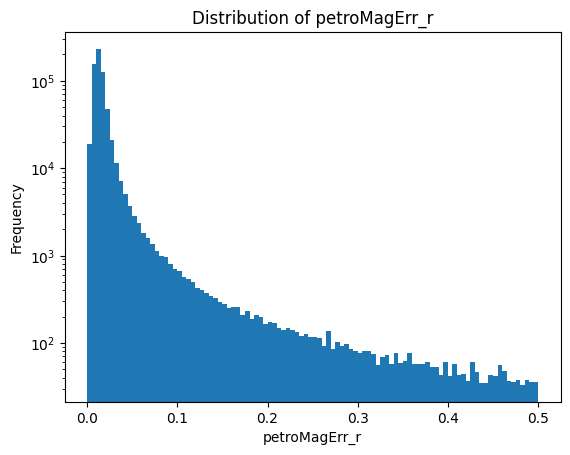

In [25]:
# We check the classification flags:
flags = ["spiral", "elliptical", "uncertain"]
print(df_raw[flags].sum())
print("rows with != 1 flag:", (df_raw[flags].sum(axis=1) != 1).sum())

# does the flag match an 80% threshold on raw or debiased votes?
for col in ["p_el", "p_el_debiased"]:
    print(col, pd.crosstab(df_raw[col] > 0.8, df_raw["elliptical"]), sep="\n")
for col in ["p_cs", "p_cs_debiased"]:
    print(col, pd.crosstab(df_raw[col] > 0.8, df_raw["spiral"]), sep="\n")

plt.hist(df_raw["petroMagErr_r"], bins=100, range=(0, 0.5))
plt.xlabel("petroMagErr_r")
plt.ylabel("Frequency")
plt.title("Distribution of petroMagErr_r")
plt.yscale("log")
plt.show()

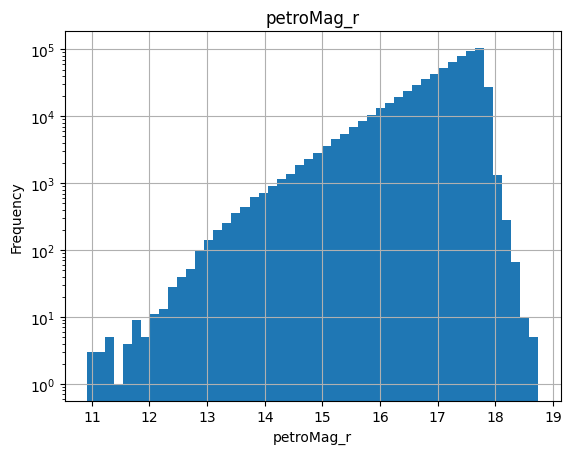

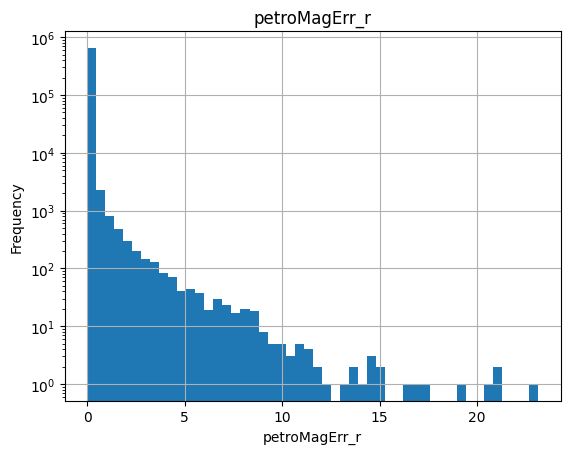

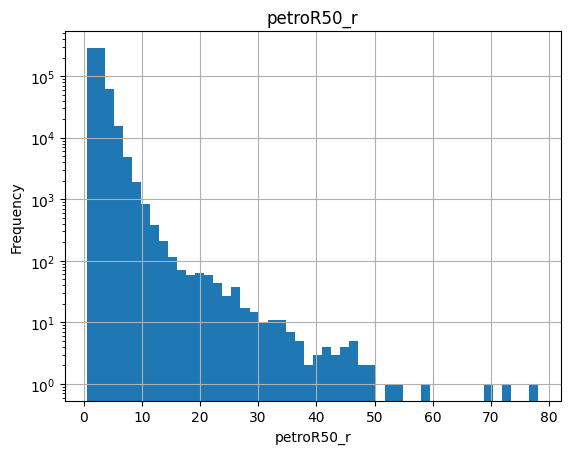

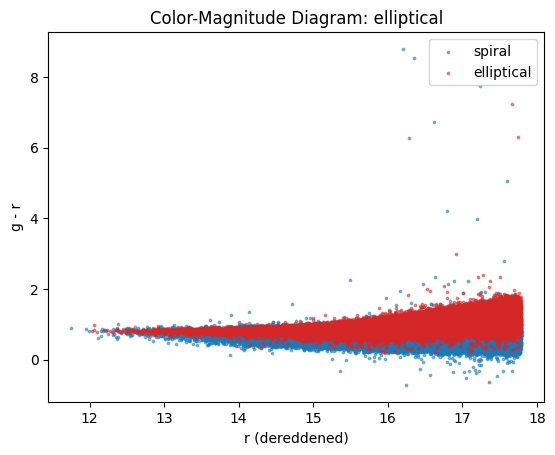

In [19]:
# We explore the photometry:
df = df_raw.copy()
df["r0"] = df["petroMag_r"] - df["extinction_r"]
df["gr"] = (df["modelMag_g"] - df["extinction_g"]) - (df["modelMag_r"] - df["extinction_r"])

for col in ["petroMag_r", "petroMagErr_r", "petroR50_r"]:
    df[col].hist(bins=50)
    plt.title(col)
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.yscale("log")
    plt.show()

# color-magnitude diagram by class
for flag, c in [("spiral", "tab:blue"), ("elliptical", "tab:red")]:
    s = df[df[flag] == 1]
    plt.scatter(s["r0"], s["gr"], s=3, c=c, label=flag, alpha=0.5)

plt.title(f"Color-Magnitude Diagram: {flag}")
plt.xlabel("r (dereddened)"); plt.ylabel("g - r")
plt.legend()
plt.show()

In [20]:
# We choose the distribution thresholds:
for t in [0.02, 0.05, 0.1, 0.2]:
    print(t, (df["petroMagErr_r"] > t).sum())

0.02 126811
0.05 30291
0.1 15723
0.2 9032


In [21]:
# We run the cleaning function and inspect the log of cuts:
df_clean, log = dp.clean_sample(df_raw)
print(len(df_raw), "->", len(df_clean))
log

658094 -> 632260


,cut,removed,remaining
0,primary only,2086,656008
1,not blended,0,656008
2,mag error,15681,640327
3,mag range,0,640327
4,enough votes,8067,632260


In [22]:
# Handle uncertain objects and check class balances:
df_labeled = df_clean[df_clean["uncertain"] == 0]
df_uncertain = df_clean[df_clean["uncertain"] == 1]

print(df_labeled[["spiral", "elliptical"]].sum())
df_labeled["spiral"].value_counts(normalize=True)

spiral        181862
elliptical     59797
dtype: int64


spiral
1    0.752556
0    0.247444
Name: proportion, dtype: float64

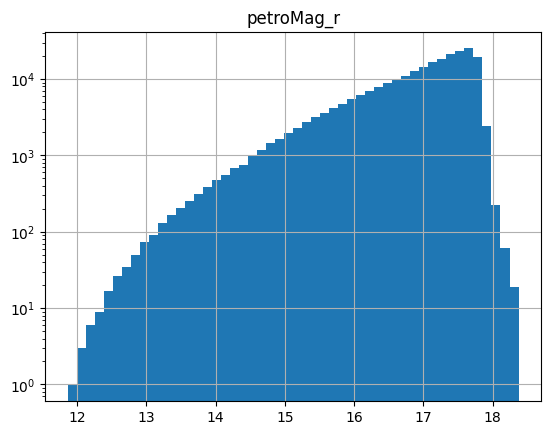

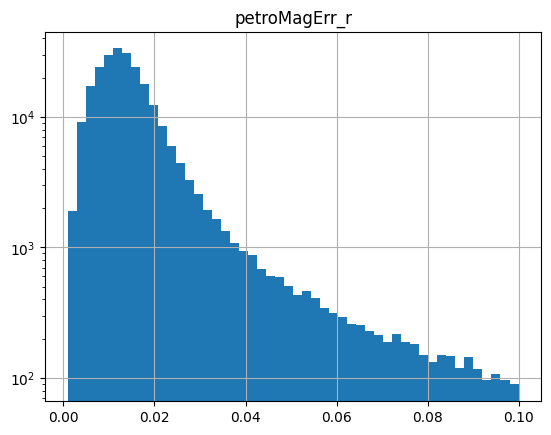

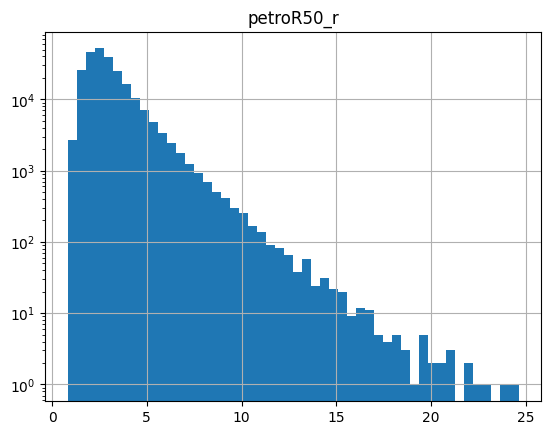

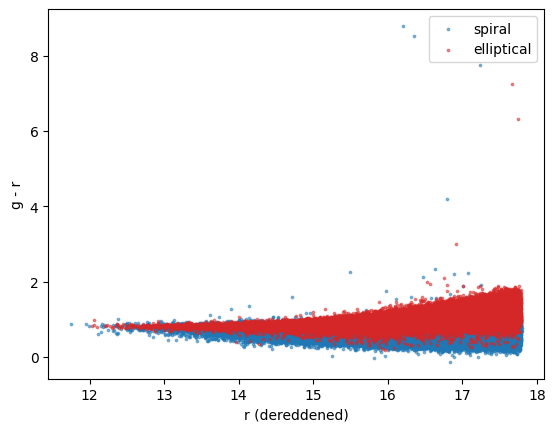

In [29]:
# We repeat the color-magnitude diagram for the cleaned sample:
df = df_labeled.copy()
df["r0"] = df["petroMag_r"] - df["extinction_r"]
df["gr"] = (df["modelMag_g"] - df["extinction_g"]) - (df["modelMag_r"] - df["extinction_r"])

import matplotlib.pyplot as plt
for col in ["petroMag_r", "petroMagErr_r", "petroR50_r"]:
    df[col].hist(bins=50); plt.title(col); plt.yscale("log"); plt.show()

# color-magnitude diagram by class
for flag, c in [("spiral", "tab:blue"), ("elliptical", "tab:red")]:
    s = df[df[flag] == 1]
    plt.scatter(s["r0"], s["gr"], s=3, c=c, label=flag, alpha=0.5)
plt.xlabel("r (dereddened)"); plt.ylabel("g - r"); plt.legend()


In [26]:
# We store the clean samples and uncertain ones separately.
df_labeled.to_csv(ROOT / "datasets/processed_datasets/galaxies_clean.csv", index=False)
df_uncertain.to_csv(ROOT / "datasets/processed_datasets/galaxies_uncertain.csv", index=False)
log.to_csv(ROOT / "datasets/processed_datasets/cleaning_log.csv", index=False)